# CMiO SC-PaCMAP results

This compact notebook keeps the benchmark contract visible: full-population CMiO data, seven unsupervised embeddings, K-means at the known class count $K=7$, and evaluation-only deposit labels. Thirty algorithm seeds are retained in memory to show seed ranges rather than a single lucky run.

The primary views are the three evaluation trajectories, the spatial-feature trade-off cloud, a 10-seed lambda-cap sensitivity check, and a 10-seed cross-group continuity check. No result files are written.

SC-PaCMAP benchmark runs use `SCPaCMAPConfig(max_target_share=1.0)`: no extra clipping below the natural bound of 1. Saved outputs have been cleared; rerun the notebook to regenerate results with this configuration. Any previously written numerical interpretations must be rechecked against the regenerated results.

In [1]:
from __future__ import annotations
import importlib, os, sys, time
from pathlib import Path

# Keep an already imported kernel's Numba pool size; use one active thread.
# On a fresh kernel, configure the pool before numerical imports.
os.environ['NUMBA_NUM_THREADS'] = str(sys.modules['numba'].config.NUMBA_NUM_THREADS) if 'numba' in sys.modules else '1'
import matplotlib.pyplot as plt
import numba, numpy as np, pandas as pd, seaborn as sns
numba.set_num_threads(1)
import pacmap, umap
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

def find_root(start=Path.cwd()):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'code' / 'sc_pacmap' / 'sc_pacmap.py').is_file(): return candidate
        nested = candidate / 'sc-pacmap-reproducibility'
        if (nested / 'code' / 'sc_pacmap' / 'sc_pacmap.py').is_file(): return nested
    raise FileNotFoundError('Repository root not found')

ROOT = find_root()
for folder in (ROOT / 'code' / 'sc_pacmap', ROOT / 'code' / 'spasne'):
    sys.path.insert(0, str(folder)) if str(folder) not in sys.path else None
from sc_pacmap import PaCMAPSettings, SCPaCMAPConfig, run_legacy_sc_pacmap, run_sc_pacmap
sc_config = SCPaCMAPConfig(max_target_share=1.0)  # No extra clipping below 1.
from spasne_adapter import python_spasne
# Keep LocalMAP's Numba resampling reproducible without an external helper file.
import importlib
from contextlib import contextmanager

@numba.njit
def seed_localmap_rng(seed):
    np.random.seed(seed)

@contextmanager
def localmap_seed(seed):
    core = importlib.import_module('pacmap.pacmap')
    original_resample = core.sample_FP_pair_nearby
    call_index = 0
    def seeded_resample(*args, **kwargs):
        nonlocal call_index
        seed_localmap_rng(seed + call_index)
        call_index += 1
        return original_resample(*args, **kwargs)
    seed_localmap_rng(seed)
    core.sample_FP_pair_nearby = seeded_resample
    try:
        yield
    finally:
        core.sample_FP_pair_nearby = original_resample

SEEDS = tuple(range(30))
SENSITIVITY_SEEDS = tuple(range(10))
N_NEIGHBORS, N_COMPONENTS, K_REFERENCE = 10, 2, 7
FEATURES = ['Y_PPM','V_PPM','LA_PPM','U_PPM','SR_PPM','SN_PPM','RB_PPM','TH_PPM','CS_PPM','CE_PPM','NB_PPM','GA_PPM','W_PPM','HF_PPM','TA_PPM','ZR_PPM','CR_PPM','PR_PPM','ND_PPM','ER_PPM','EU_PPM','SM_PPM','YB_PPM','TB_PPM','HO_PPM','GD_PPM','DY_PPM','LU_PPM','BA_PPM','SIO2_WT_PERCENT','TIO2_WT_PERCENT','NA2O_WT_PERCENT','K2O_WT_PERCENT','AL2O3_WT_PERCENT','TM_PPM']
data = pd.read_csv(ROOT / 'data' / 'processed' / 'cmio_sc_pacmap_ready.csv')
coords = data[['x','y','z']].to_numpy(float)
truth = data['label_id'].to_numpy(int)
features = StandardScaler().fit_transform(data[FEATURES]).astype(np.float32)
xyz = StandardScaler().fit_transform(coords)
features_xyz = np.column_stack([features, xyz])
tss = float(np.sum((features - features.mean(0, keepdims=True)) ** 2))
spatial_neighbors = NearestNeighbors(n_neighbors=N_NEIGHBORS + 1, n_jobs=1).fit(coords).kneighbors(coords, return_distance=False)[:, 1:]
settings_base = dict(n_components=2, n_neighbors=N_NEIGHBORS, mn_ratio=.5, fp_ratio=2., learning_rate=1., num_iters=(100,100,250), knn_backend='faiss', verbose=False)
METHODS = ['UMAP + XYZ','PaCMAP + XYZ','LocalMAP + XYZ','PaCMAP feature-only','SC-PaCMAP replacement','SC-PaCMAP full graph','SpaSNE']
print(f'{len(data)} samples | {len(FEATURES)} features | {data.group_id.nunique()} groups | K={K_REFERENCE}')
K_VALUES = range(2, 11)
COLORS = dict(zip(METHODS, ['#D55E00', '#56B4E9', '#009E73', '#7A5195', '#E15759', '#E60049', '#D4A900']))
MARKERS = dict(zip(METHODS, ['o', '^', 'v', 'P', 'h', '*', 'X']))
NEIGHBOR_VALUES = (10, 15, 20)  # Embedding neighborhoods in stability/cloud sections only
DATASET_TITLE = 'CMiO'


c:\Users\weihong\Desktop\SC-PACMAP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1551 samples | 35 features | 38 groups | K=7


## Data walk-through

Coordinates and labels are retained for evaluation and plotting. Only standardized geochemistry, and where stated standardized XYZ, enters an embedding.

,label_id,LABEL_deposit_group,samples
0,0,Alkali-calcic,22
1,1,IOCG,364
2,2,Laterite,306
3,3,Metasomatic iron,111
4,4,Orogenic,252
5,5,Phosphorite,216
6,6,Sediment-hosted,280


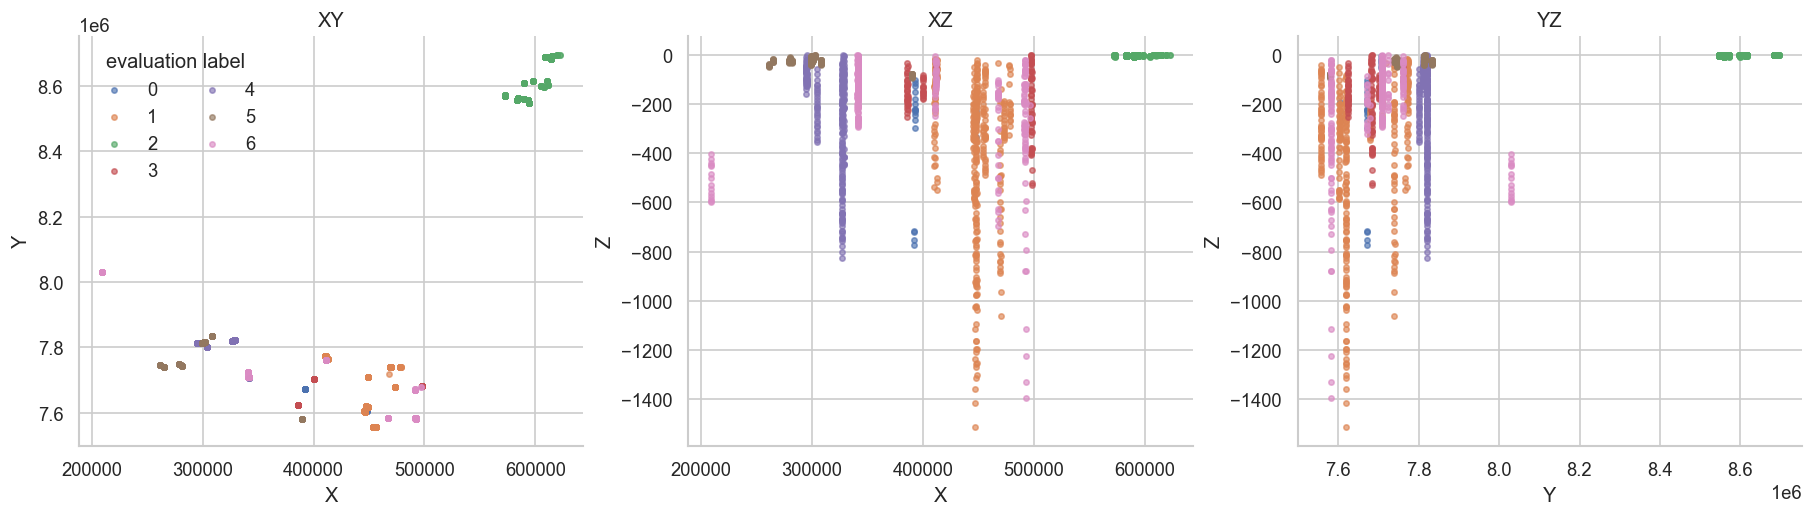

In [2]:
from IPython.display import display

display(data.groupby(['label_id','LABEL_deposit_group'], observed=True).size().rename('samples').reset_index())
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for ax, pair in zip(axes, [('x','y'),('x','z'),('y','z')]):
    for label in sorted(data.label_id.unique()):
        mask = truth == label; ax.scatter(data.loc[mask,pair[0]], data.loc[mask,pair[1]], s=10, alpha=.65, label=str(label))
    ax.set(xlabel=pair[0].upper(), ylabel=pair[1].upper(), title=f'{pair[0].upper()}{pair[1].upper()}')
axes[0].legend(frameon=False, ncol=2, title='evaluation label')
plt.show()

## One seed: embeddings and K=7 evaluation

Each panel colors the raw 2-D embedding by the evaluation-only true label. K-means
still evaluates the same embedding at $K=7$ for the result table below. Cluster IDs
do not correspond between methods, and ground-truth labels are used only for plotting
and the ARI in the result table.

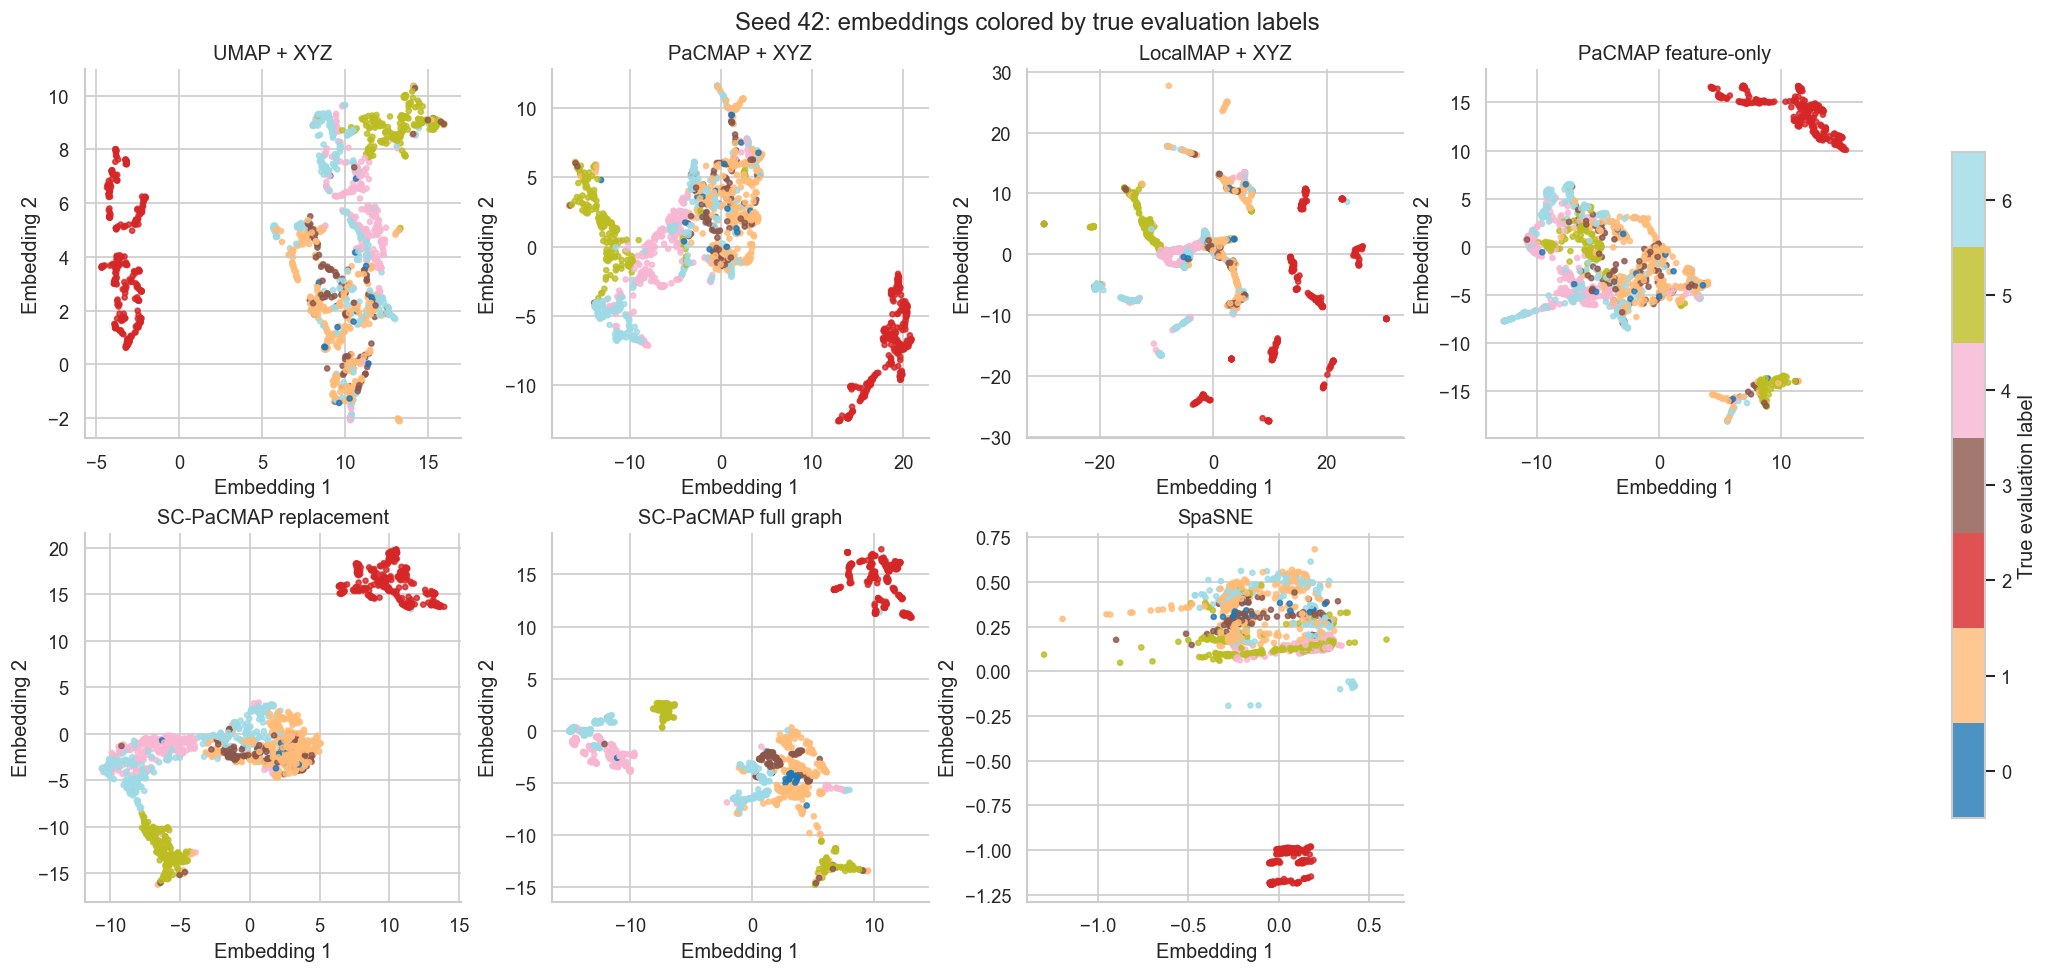

,method,K,H_per_sample,WCSS_TSS,ARI
0,UMAP + XYZ,7,0.5148,0.5914,0.3416
1,PaCMAP + XYZ,7,0.5365,0.5920,0.3427
2,LocalMAP + XYZ,7,0.4857,0.6142,0.3542
3,PaCMAP feature-only,7,0.6679,0.5611,0.2544
4,SC-PaCMAP replacement,7,0.2210,0.6311,0.5798
5,SC-PaCMAP full graph,7,0.1750,0.5995,0.5716
6,SpaSNE,7,0.3766,0.5739,0.4247


Automatic spatial-strength lambda: 0.457


In [3]:
def fit_embeddings(seed, feature_values=features, coordinate_values=coords, *,
                   n_neighbors=N_NEIGHBORS, spasne_embedding=None):
    numba.set_num_threads(1)
    features_with_coordinates = np.column_stack([feature_values, StandardScaler().fit_transform(coordinate_values)])
    settings = PaCMAPSettings(random_state=seed, **{**settings_base, 'n_neighbors': n_neighbors})
    pacmap_args = {'n_components':2, 'n_neighbors':n_neighbors, 'MN_ratio':.5, 'FP_ratio':2., 'distance':'euclidean', 'lr':1., 'num_iters':(100,100,250), 'apply_pca':True, 'random_state':seed, 'save_tree':False, 'knn_backend':'faiss'}
    out = {}
    out['UMAP + XYZ'] = umap.UMAP(n_neighbors=n_neighbors, n_components=2, metric='euclidean', learning_rate=1., random_state=seed, n_jobs=1).fit_transform(features_with_coordinates)
    out['PaCMAP + XYZ'] = pacmap.PaCMAP(**pacmap_args).fit_transform(features_with_coordinates, init='pca', save_pairs=False)
    with localmap_seed(seed):
        out['LocalMAP + XYZ'] = pacmap.LocalMAP(**{**pacmap_args, 'low_dist_thres':10}).fit_transform(np.ascontiguousarray(features_with_coordinates, dtype=np.float64), init='pca', save_pairs=False)
    out['PaCMAP feature-only'] = pacmap.PaCMAP(**pacmap_args).fit_transform(feature_values, init='pca', save_pairs=False)
    replacement, _ = run_legacy_sc_pacmap(feature_values, coordinate_values, settings); out['SC-PaCMAP replacement'] = replacement.embedding
    full, diagnostics = run_sc_pacmap(feature_values, coordinate_values, settings, config=sc_config); out['SC-PaCMAP full graph'] = full.embedding
    if spasne_embedding is None:
        out['SpaSNE'] = python_spasne(feature_values, coordinate_values, random_state=seed, alpha=10., beta=5., exaggeration=4, perplexity=50, theta=.5, max_iter=1000, use_pca=True, spasne_dir=ROOT / 'code' / 'spasne' / 'spasne_original')
    else:
        out['SpaSNE'] = spasne_embedding
    return out, diagnostics


def entropy(labels, neighbors=spatial_neighbors):
    total = 0.
    for n in neighbors:
        counts = np.bincount(labels[n])
        p = counts[counts > 0] / neighbors.shape[1]
        total -= float(np.sum(p * np.log(p)))
    return total / len(labels)


def wcss(labels, k=K_REFERENCE, feature_values=features, total_ss=tss):
    centers = np.vstack([feature_values[labels == j].mean(0) for j in range(k)])
    return float(np.sum((feature_values - centers[labels])**2)) / total_ss


def evaluate(labels, k, feature_values=features, neighbors=spatial_neighbors,
             label_truth=truth, total_ss=tss):
    return {'H_per_sample': entropy(labels, neighbors),
            'WCSS_TSS': wcss(labels, k, feature_values, total_ss),
            'ARI': adjusted_rand_score(label_truth, labels)}

one_seed_embeddings, one_seed_diag = fit_embeddings(42)
# Convert stored embeddings to float64 before K-means evaluation.
one_seed_embeddings = {m: np.asarray(y, dtype=np.float64) for m, y in one_seed_embeddings.items()}
one_seed_rows = []
fig, axes = plt.subplots(2, 4, figsize=(17, 8), constrained_layout=True)
true_label_cmap = plt.get_cmap('tab20', len(np.unique(truth)))
for ax, method in zip(axes.flat, METHODS):
    embedding = one_seed_embeddings[method]
    cluster_labels = KMeans(n_clusters=K_REFERENCE, init='k-means++', n_init=20,
                            random_state=1000 + K_REFERENCE).fit_predict(embedding)
    one_seed_rows.append({'method': method, 'K': K_REFERENCE, **evaluate(cluster_labels, K_REFERENCE)})
    points = ax.scatter(embedding[:, 0], embedding[:, 1], c=truth,
                        cmap=true_label_cmap, vmin=truth.min() - .5, vmax=truth.max() + .5, s=9, alpha=.8)
    ax.set(title=method, xlabel='Embedding 1', ylabel='Embedding 2')
axes.flat[-1].set_visible(False)
fig.colorbar(points, ax=list(axes.flat[:-1]), ticks=sorted(np.unique(truth)),
             label='True evaluation label', shrink=.8)
fig.suptitle('Seed 42: embeddings colored by true evaluation labels')
plt.show()
one_seed_results = pd.DataFrame(one_seed_rows)
display(one_seed_results.round(4))
print(f'Automatic spatial-strength lambda: {one_seed_diag.spatial_strength_lambda:.3f}')

## Thirty-seed evaluation curves: neighborhood robustness

Embedding neighborhood sizes **10, 15, and 20** use the same **30 algorithm seeds (0?29)** on the same full dataset. The figure has one row per neighborhood size and one column per metric. Lines show seed medians; shading shows observed seed min?max ranges, not confidence intervals. Results are kept separate by neighborhood size, rather than pooled into a 90-run band.

Lowercase neighborhood size is distinct from **K**, the K-means cluster count swept along the horizontal axis. The reference line marks the dataset's true class count. K-means uses raw 2-D embeddings, 20 initializations, and a fixed clustering seed for each K. The geographic evaluation window remains **10 neighbors** in every panel so entropy measures the same spatial scale.

The neighborhood setting changes UMAP, PaCMAP, LocalMAP, and both SC-PaCMAP variants together. SpaSNE has no equivalent n_neighbors parameter: its perplexity stays at 50, and each seed's result is reused across rows as the same baseline. SC-PaCMAP uses max_target_share=1.0 throughout.

One-seed embeddings, lambda-cap sensitivity, and cross-group/deposit checks retain the default neighborhood size 10. This sweep tests sensitivity to neighborhood choice; it does not by itself guarantee stronger performance.

Completed algorithm seed 0, n_neighbors=10


Completed algorithm seed 0, n_neighbors=15


Completed algorithm seed 0, n_neighbors=20


Completed algorithm seed 1, n_neighbors=10


Completed algorithm seed 1, n_neighbors=15


...

Completed algorithm seed 28, n_neighbors=15


Completed algorithm seed 28, n_neighbors=20


Completed algorithm seed 29, n_neighbors=10


Completed algorithm seed 29, n_neighbors=15


Completed algorithm seed 29, n_neighbors=20


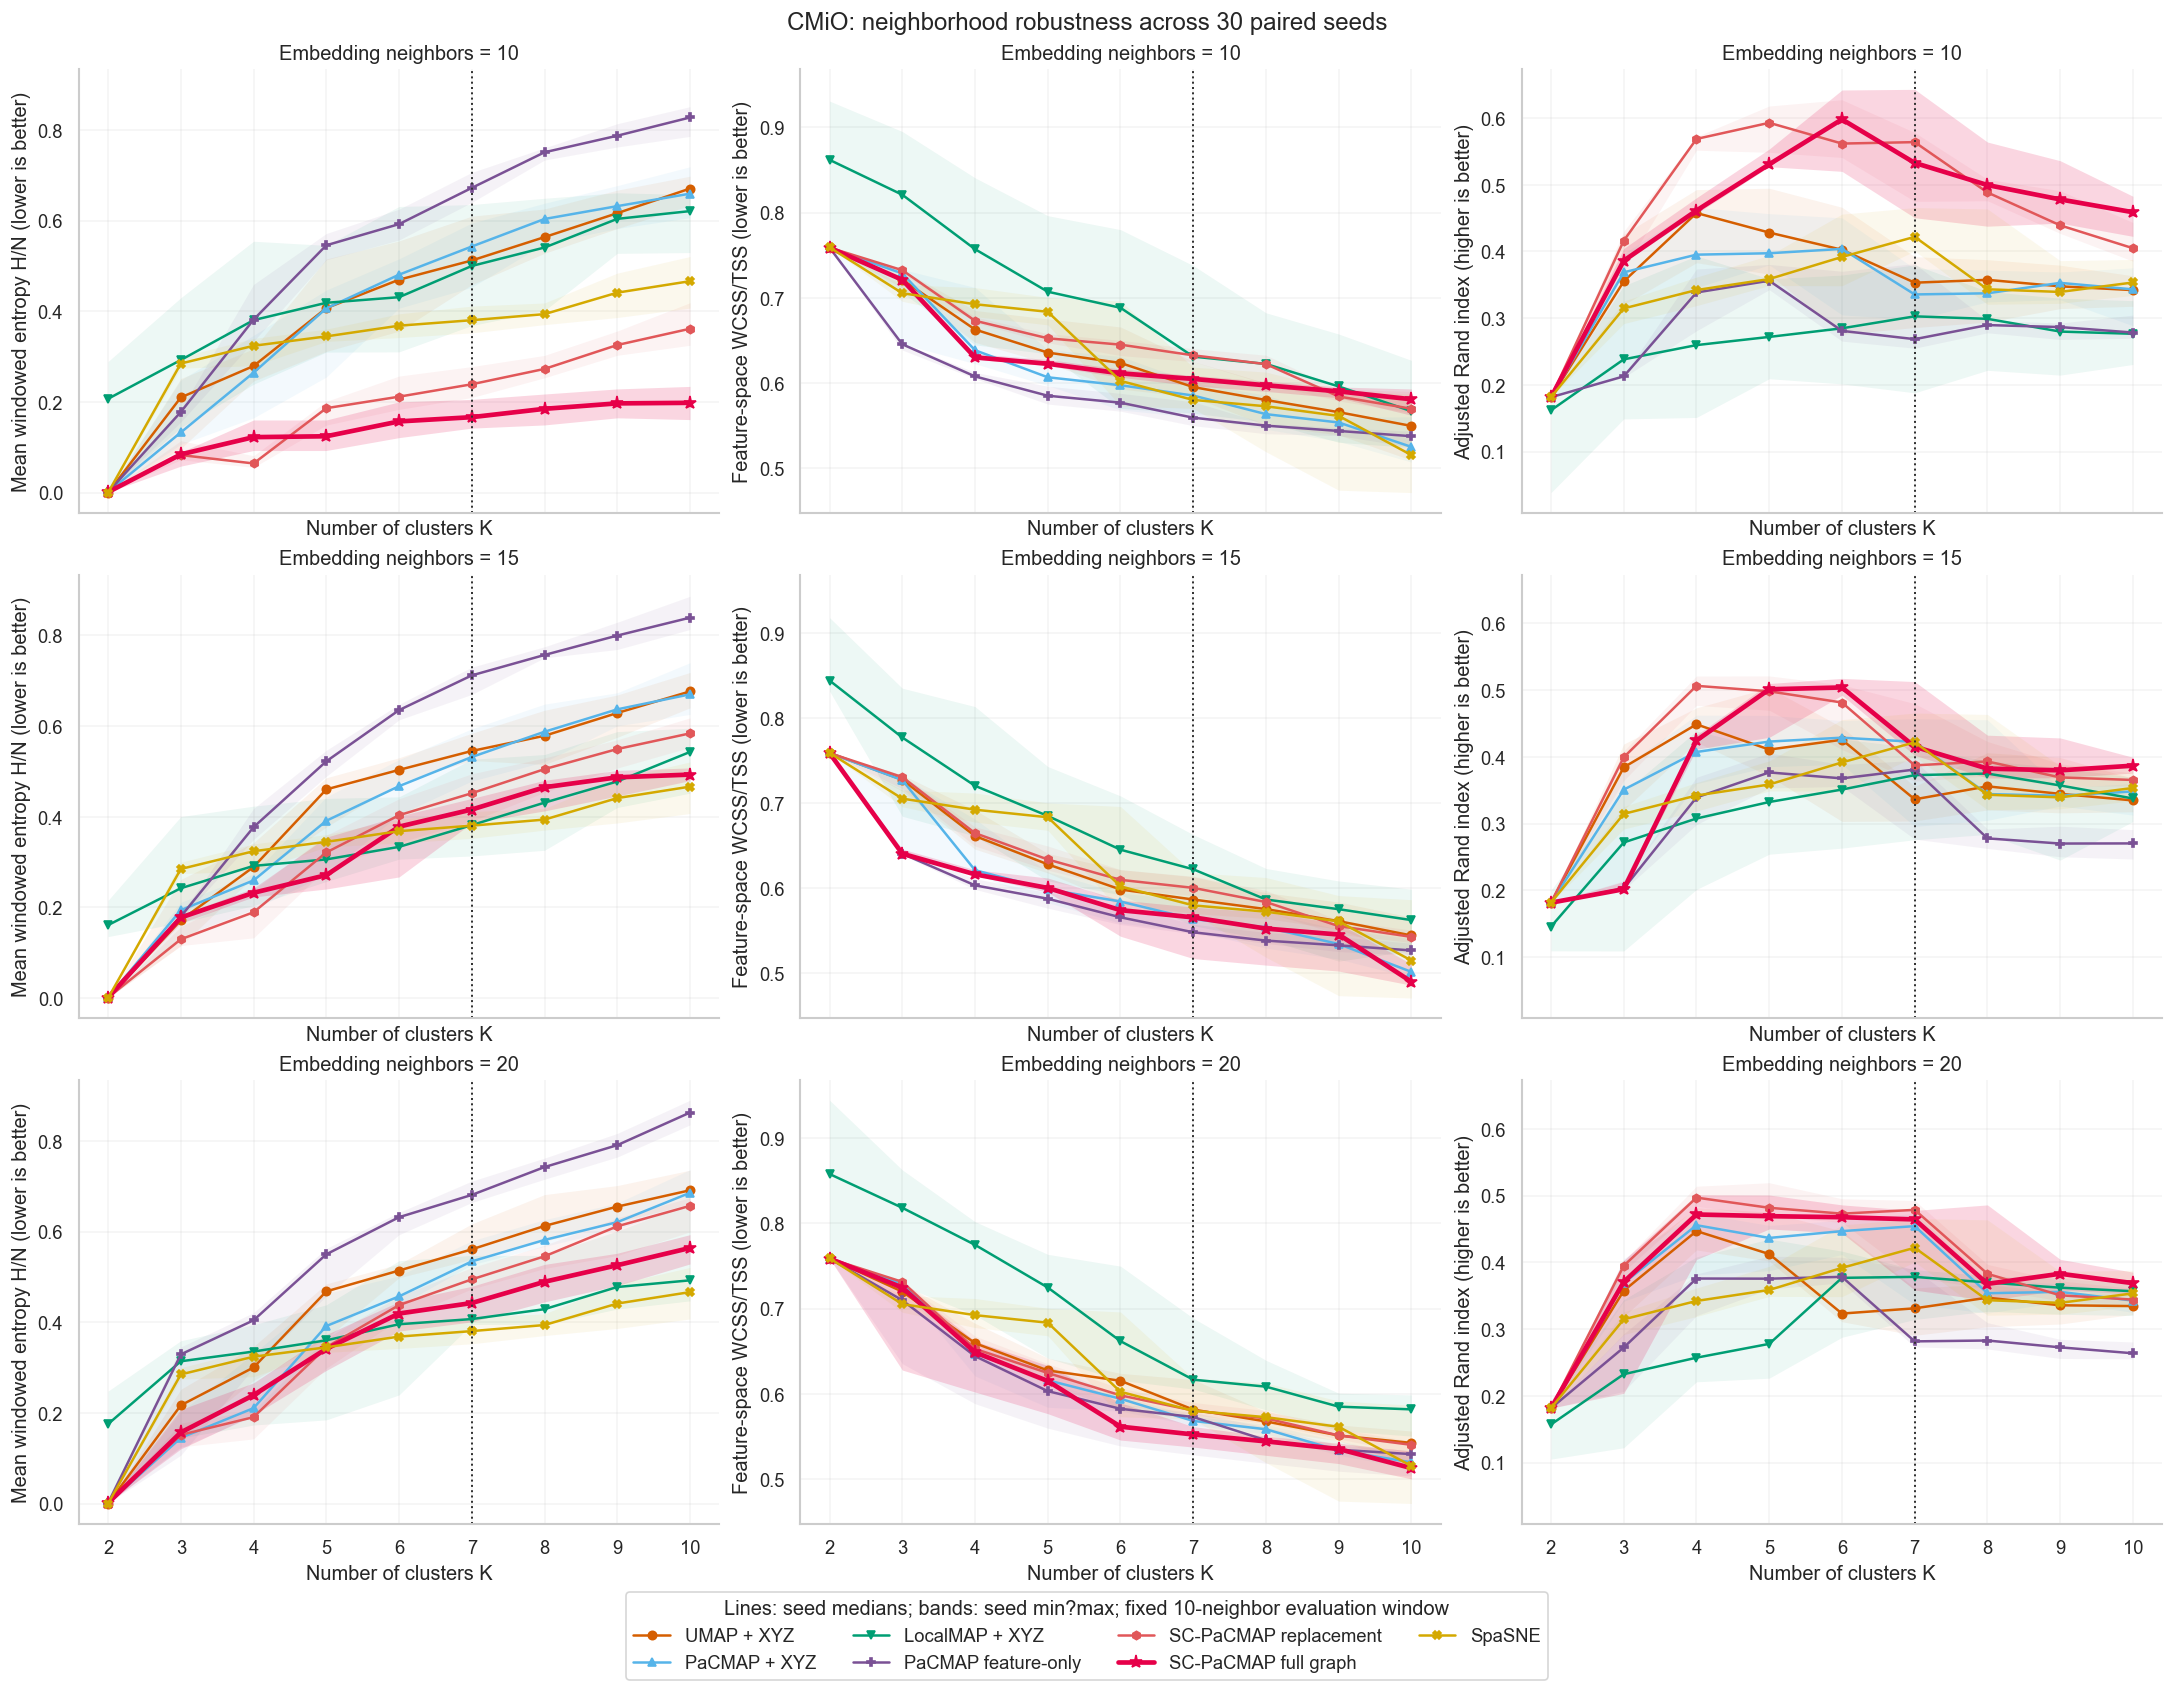

In [4]:
rows = []
for seed in SEEDS:
    # SpaSNE uses fixed perplexity=50, with no n_neighbors parameter.
    # Reuse that seed's baseline across neighborhood panels, not as independent runs.
    spasne_embedding = None
    for n_neighbors in NEIGHBOR_VALUES:
        embeddings, _ = fit_embeddings(seed, n_neighbors=n_neighbors,
                                       spasne_embedding=spasne_embedding)
        spasne_embedding = embeddings['SpaSNE']
        for method in METHODS:
            for k in K_VALUES:
                labels = KMeans(n_clusters=k, init='k-means++', n_init=20,
                                random_state=1000 + k).fit_predict(
                                    np.asarray(embeddings[method], dtype=np.float64))
                rows.append({'seed': seed, 'n_neighbors': n_neighbors,
                             'method': method, 'K': k, **evaluate(labels, k)})
        print(f'Completed algorithm seed {seed}, n_neighbors={n_neighbors}', flush=True)
results = pd.DataFrame(rows)
range_results = results
assert len(results) == len(SEEDS) * len(NEIGHBOR_VALUES) * len(METHODS) * len(K_VALUES)
assert not results.duplicated(['seed', 'n_neighbors', 'method', 'K']).any()
assert results.groupby(['n_neighbors', 'method', 'K']).seed.nunique().eq(len(SEEDS)).all()
assert np.isfinite(results[['H_per_sample', 'WCSS_TSS', 'ARI']].to_numpy()).all()

metric_specs = [('H_per_sample', 'Mean windowed entropy H/N', 'lower is better'),
                ('WCSS_TSS', 'Feature-space WCSS/TSS', 'lower is better'),
                ('ARI', 'Adjusted Rand index', 'higher is better')]
fig, axes = plt.subplots(len(NEIGHBOR_VALUES), 3, figsize=(18, 14),
                         sharex=True, sharey='col', squeeze=False, constrained_layout=True)
for row, n_neighbors in enumerate(NEIGHBOR_VALUES):
    neighborhood_results = range_results[range_results.n_neighbors == n_neighbors]
    for ax, (metric, ylabel, direction) in zip(axes[row], metric_specs):
        for method in METHODS:
            summary = neighborhood_results[neighborhood_results.method == method].groupby('K')[metric].agg(['median', 'min', 'max'])
            primary = method == 'SC-PaCMAP full graph'
            ax.fill_between(summary.index, summary['min'], summary['max'], color=COLORS[method],
                            alpha=.16 if primary else .07, linewidth=0)
            ax.plot(summary.index, summary['median'], color=COLORS[method], marker=MARKERS[method],
                    linewidth=2.8 if primary else 1.5, markersize=8 if primary else 5, label=method)
        ax.axvline(K_REFERENCE, color='#333333', ls=':', lw=1.2)
        ax.set(xlabel='Number of clusters K', ylabel=f'{ylabel} ({direction})',
               title=f'Embedding neighbors = {n_neighbors}', xticks=list(K_VALUES))
        ax.grid(alpha=.2)
fig.suptitle(f'{DATASET_TITLE}: neighborhood robustness across {len(SEEDS)} paired seeds')
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='outside lower center', ncol=4,
           title='Lines: seed medians; bands: seed min?max; fixed 10-neighbor evaluation window')
plt.show()


## Combined trade-off cloud at the true class count

One plot combines all seed results at **K=K_REFERENCE**. **Color identifies the method; shape identifies embedding neighborhood size:** circles for 10, triangles for 15, and squares for 20. Each neighborhood-dependent method contributes **90 small transparent points** (30 paired seeds ? three settings). SpaSNE contributes **30 diamond points**, shown once because its fixed-perplexity results are reused across neighborhood settings.

Large outlined markers show the median for each method?neighborhood combination; set `SHOW_CLOUD_MEDIANS=False` to display only the seed points. The geographic evaluation window stays fixed at 10 neighbors. Lower-left is better jointly; these points show paired algorithm runs, not independent datasets.

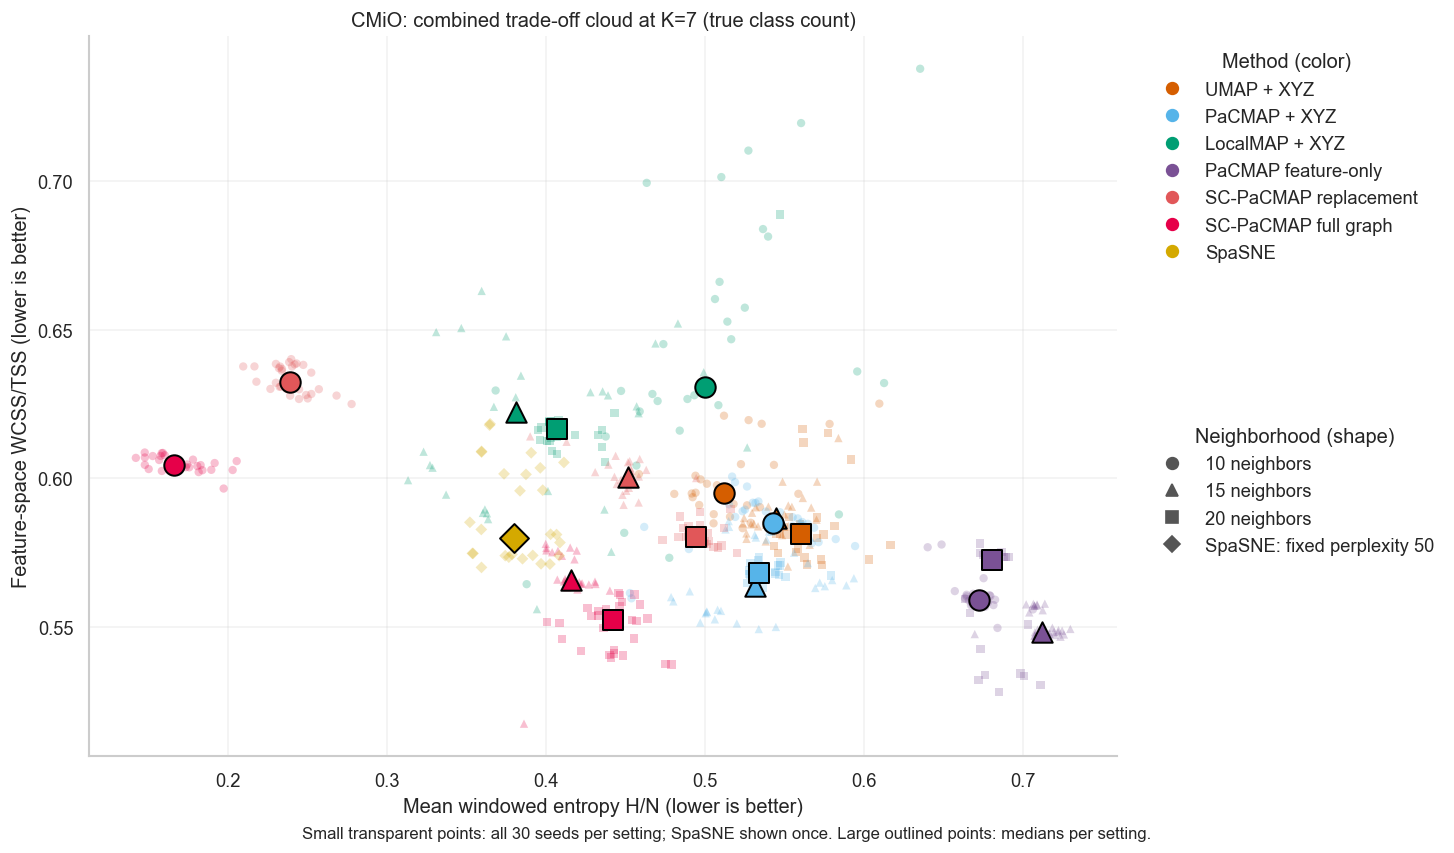

In [5]:
from matplotlib.lines import Line2D

cloud = results[results.K == K_REFERENCE].copy()
# SpaSNE is the same fixed-perplexity run repeated under each neighborhood label.
cloud = cloud[(cloud.method != 'SpaSNE') | (cloud.n_neighbors == NEIGHBOR_VALUES[0])]
cloud_medians = cloud.groupby(['n_neighbors', 'method'])[['H_per_sample', 'WCSS_TSS']].median()
NEIGHBOR_MARKERS = {10: 'o', 15: '^', 20: 's'}
SHOW_CLOUD_MEDIANS = True
fig, ax = plt.subplots(figsize=(12, 7), constrained_layout=True)
for method in METHODS:
    neighbor_settings = (NEIGHBOR_VALUES[0],) if method == 'SpaSNE' else NEIGHBOR_VALUES
    for n_neighbors in neighbor_settings:
        part = cloud[(cloud.method == method) & (cloud.n_neighbors == n_neighbors)]
        marker = 'D' if method == 'SpaSNE' else NEIGHBOR_MARKERS[n_neighbors]
        ax.scatter(part.H_per_sample, part.WCSS_TSS, color=COLORS[method],
                   marker=marker, s=25, alpha=.25, edgecolors='none')
        if SHOW_CLOUD_MEDIANS:
            median = cloud_medians.loc[(n_neighbors, method)]
            ax.scatter(median.H_per_sample, median.WCSS_TSS, color=COLORS[method],
                       marker=marker, s=150, edgecolor='black', linewidth=1.2, zorder=4)

ax.set(xlabel='Mean windowed entropy H/N (lower is better)',
       ylabel='Feature-space WCSS/TSS (lower is better)',
       title=f'{DATASET_TITLE}: combined trade-off cloud at K={K_REFERENCE} (true class count)')
ax.grid(alpha=.25)
method_handles = [Line2D([], [], color=COLORS[method], marker='o', linestyle='None',
                         markersize=7, label=method) for method in METHODS]
method_legend = ax.legend(handles=method_handles, title='Method (color)', frameon=False,
                          bbox_to_anchor=(1.02, 1), loc='upper left')
ax.add_artist(method_legend)
neighbor_handles = [Line2D([], [], color='#555555', marker=NEIGHBOR_MARKERS[n],
                           linestyle='None', markersize=7, label=f'{n} neighbors')
                    for n in NEIGHBOR_VALUES]
neighbor_handles.append(Line2D([], [], color='#555555', marker='D', linestyle='None',
                               markersize=7, label='SpaSNE: fixed perplexity 50'))
ax.legend(handles=neighbor_handles, title='Neighborhood (shape)', frameon=False,
          bbox_to_anchor=(1.02, .48), loc='upper left')
caption = f'Small transparent points: all {len(SEEDS)} seeds per setting; SpaSNE shown once.'
if SHOW_CLOUD_MEDIANS:
    caption += ' Large outlined points: medians per setting.'
fig.supxlabel(caption, fontsize=10)
plt.show()


## Lambda-cap sensitivity at $K=7$

Ten algorithm seeds sweep `SCPaCMAPConfig(max_target_share=...)` on the fixed
full dataset. This parameter caps both the automatically inferred lambda used
in the share calculation and the final Phase-3 spatial-attraction share; it does
not replace lambda with a manually fixed value. The benchmark uses max_target_share=1.0: no extra clipping below the natural bound of 1. The sweep includes that baseline.
The dashed line marks the data-derived automatic lambda for reference.

Lines show seed medians; shading shows min-max seed ranges. Here the two evaluation
scores are percentages (higher is better): spatial contiguity is
$100(1-(H/N)/\log K)$ and multivariate delineation is $100(1-\mathrm{WCSS}/\mathrm{TSS})$.

Completed sensitivity seed 0
Completed sensitivity seed 1
Completed sensitivity seed 2
Completed sensitivity seed 3
Completed sensitivity seed 4
Completed sensitivity seed 5
Completed sensitivity seed 6
Completed sensitivity seed 7
Completed sensitivity seed 8
Completed sensitivity seed 9


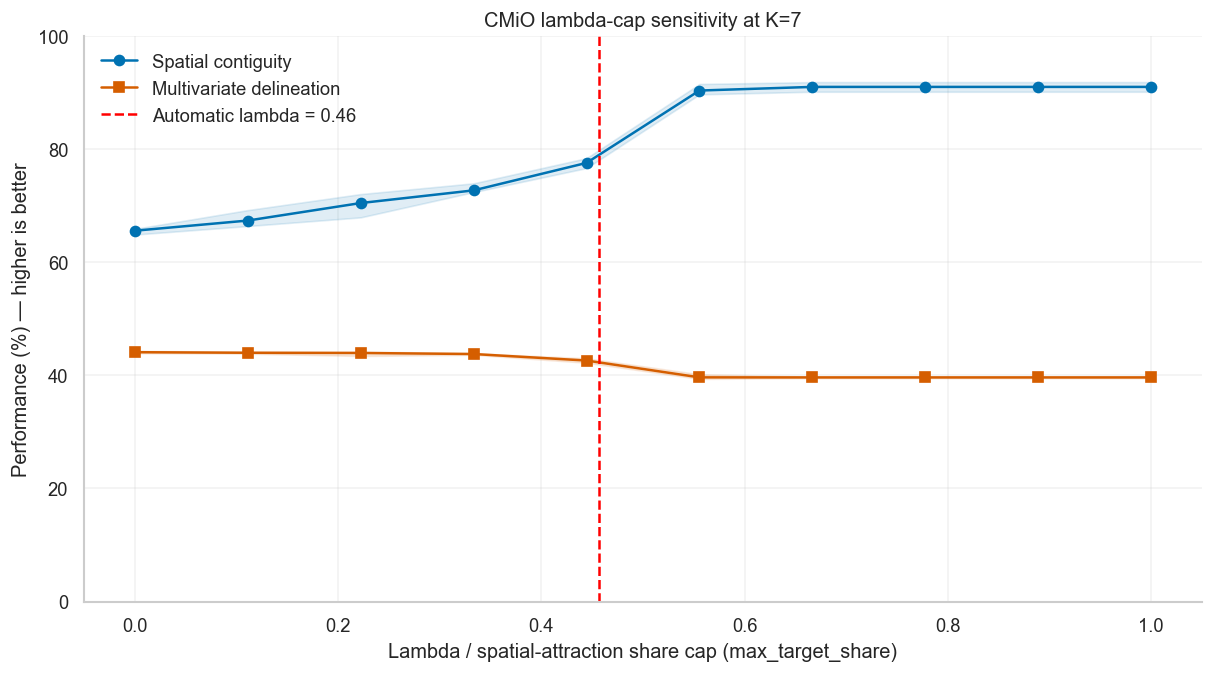

In [6]:
lambda_caps = np.linspace(0., 1.0, 10)  # Include the no-extra-clipping baseline.
lambda_rows = []
for seed in SENSITIVITY_SEEDS:
    settings = PaCMAPSettings(random_state=seed, **settings_base)
    for cap in lambda_caps:
        result, diag = run_sc_pacmap(features, coords, settings,
                                    config=SCPaCMAPConfig(max_target_share=float(cap)))
        labels = KMeans(n_clusters=K_REFERENCE, init='k-means++', n_init=20,
                        random_state=1000 + K_REFERENCE).fit_predict(result.embedding)
        metrics = evaluate(labels, K_REFERENCE)
        lambda_rows.append({'seed': seed, 'lambda_cap': cap,
                            'automatic_lambda': diag.spatial_strength_lambda,
                            'target_share': diag.automatic_target_share,
                            'spatial': 100 * (1 - metrics['H_per_sample'] / np.log(K_REFERENCE)),
                            'multivariate': 100 * (1 - metrics['WCSS_TSS'])})
    print(f'Completed sensitivity seed {seed}', flush=True)
lambda_results = pd.DataFrame(lambda_rows)
automatic_lambda = float(lambda_results.automatic_lambda.median())
fig, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
for metric, label, color, marker in [
    ('spatial', 'Spatial contiguity', '#0072B2', 'o'),
    ('multivariate', 'Multivariate delineation', '#D55E00', 's'),
]:
    summary = lambda_results.groupby('lambda_cap')[metric].agg(['median', 'min', 'max'])
    ax.fill_between(summary.index, summary['min'], summary['max'], color=color, alpha=.12)
    ax.plot(summary.index, summary['median'], color=color, marker=marker, label=label)
ax.axvline(automatic_lambda, color='red', ls='--', label=f'Automatic lambda = {automatic_lambda:.2f}')
ax.set(xlabel='Lambda / spatial-attraction share cap (max_target_share)',
       ylabel='Performance (%) — higher is better', ylim=(0, 100),
       title=f'CMiO lambda-cap sensitivity at K={K_REFERENCE}')
ax.legend(frameon=False)
ax.grid(alpha=.25)
plt.show()

## Cross-group leave-one-out continuity

For the cross-hole continuity check, each sample $i$ is evaluated using only spatial neighbours from different groups. For CMiO, `group_id` is the available sampling-group field; for drill-core data this same calculation is the cross-hole check. The focal sample is always excluded.

,median,min,max
method,,,
LocalMAP + XYZ,68.65,66.64,75.81
PaCMAP + XYZ,67.75,63.84,72.99
PaCMAP feature-only,67.01,64.28,68.15
SC-PaCMAP full graph,93.88,89.82,96.00
SC-PaCMAP replacement,83.43,82.04,86.59
SpaSNE,81.87,75.71,84.34
UMAP + XYZ,72.15,67.79,75.59


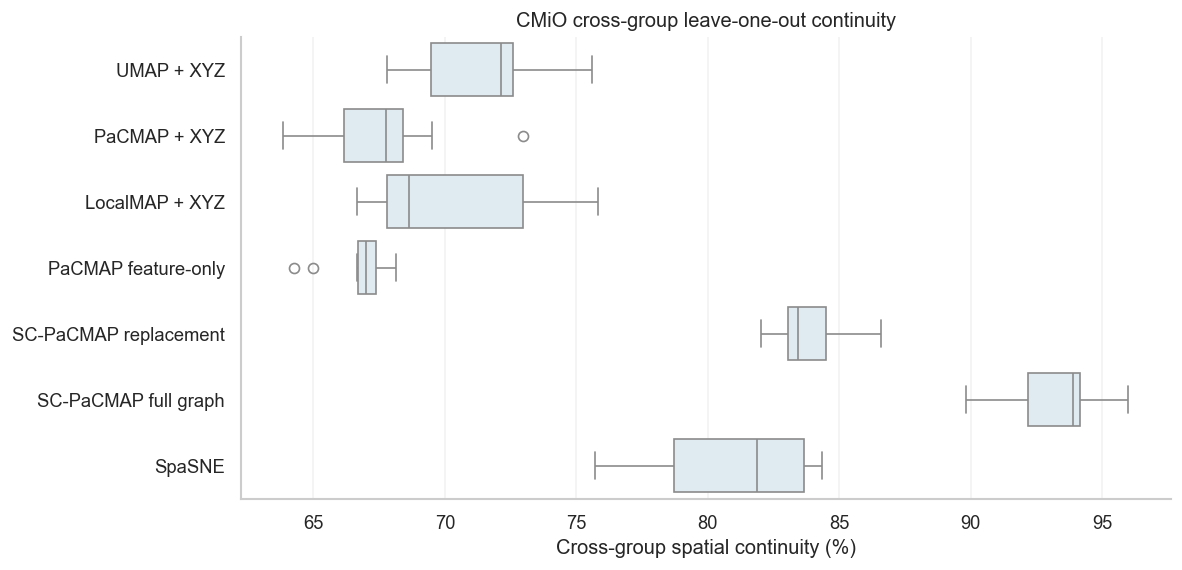

,primary,comparator,paired_seeds,median_difference,primary_wins,ties,wilcoxon_statistic,p_greater,holm_p
0,SC-PaCMAP full graph,UMAP + XYZ,10,21.5283,10,0,55.0,0.001,0.0059
1,SC-PaCMAP full graph,PaCMAP + XYZ,10,24.5766,10,0,55.0,0.001,0.0059
2,SC-PaCMAP full graph,LocalMAP + XYZ,10,23.0059,10,0,55.0,0.001,0.0059
3,SC-PaCMAP full graph,PaCMAP feature-only,10,26.7320,10,0,55.0,0.001,0.0059
4,SC-PaCMAP full graph,SC-PaCMAP replacement,10,9.4781,10,0,55.0,0.001,0.0059
5,SC-PaCMAP full graph,SpaSNE,10,11.7262,10,0,55.0,0.001,0.0059


One-sided paired Wilcoxon tests whether SC-PaCMAP full graph has higher cross-group continuity than each comparator; Holm-adjusted alpha = 0.05.
Statistically higher than every comparator: True


In [7]:
from scipy.stats import wilcoxon


def paired_wilcoxon_table(frame, value_column, primary_method='SC-PaCMAP full graph'):
    rows = []
    comparator_methods = [method for method in METHODS if method != primary_method]
    for comparator in comparator_methods:
        paired = frame.pivot(index='seed', columns='method', values=value_column).dropna()
        differences = paired[primary_method] - paired[comparator]
        if np.allclose(differences, 0.0):
            statistic, p_value = 0.0, 1.0
        else:
            test = wilcoxon(
                differences,
                alternative='greater',
                zero_method='wilcox',
                method='auto',
            )
            statistic, p_value = float(test.statistic), float(test.pvalue)
        rows.append({
            'primary': primary_method,
            'comparator': comparator,
            'paired_seeds': len(differences),
            'median_difference': float(np.median(differences)),
            'primary_wins': int(np.sum(differences > 0)),
            'ties': int(np.sum(differences == 0)),
            'wilcoxon_statistic': statistic,
            'p_greater': p_value,
        })
    results = pd.DataFrame(rows).sort_values('p_greater').reset_index(drop=True)
    running_maximum = 0.0
    adjusted = []
    for rank, p_value in enumerate(results['p_greater']):
        corrected = min(1.0, p_value * (len(results) - rank))
        running_maximum = max(running_maximum, corrected)
        adjusted.append(running_maximum)
    results['holm_p'] = adjusted
    return results


def cross_group_neighbors(coordinates, groups, n=N_NEIGHBORS):
    distances = ((coordinates[:, None, :] - coordinates[None, :, :]) ** 2).sum(2)
    distances[groups[:, None] == groups[None, :]] = np.inf
    np.fill_diagonal(distances, np.inf)
    return np.argsort(distances, axis=1)[:, :n]

cross_neighbors = cross_group_neighbors(coords, data.group_id.astype(str).to_numpy())
holdout_rows = []
for seed in SENSITIVITY_SEEDS:
    embeddings, _ = fit_embeddings(seed)
    for method in METHODS:
        labels = KMeans(
            n_clusters=K_REFERENCE,
            n_init=20,
            random_state=1000 + K_REFERENCE,
        ).fit_predict(embeddings[method])
        holdout_rows.append({
            'seed': seed,
            'method': method,
            'cross_group_spatial': 100 * (
                1 - entropy(labels, cross_neighbors) / np.log(K_REFERENCE)
            ),
        })

holdout = pd.DataFrame(holdout_rows)
display(
    holdout.groupby('method').cross_group_spatial
    .agg(['median', 'min', 'max'])
    .round(2)
)

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=holdout,
    x='cross_group_spatial',
    y='method',
    color='#DCEAF4',
)
plt.xlabel('Cross-group spatial continuity (%)')
plt.ylabel('')
plt.title('CMiO cross-group leave-one-out continuity')
plt.grid(axis='x', alpha=.25)
plt.show()

cross_group_tests = paired_wilcoxon_table(holdout, 'cross_group_spatial')
display(cross_group_tests.round(4))
print(
    'One-sided paired Wilcoxon tests whether SC-PaCMAP full graph has '
    'higher cross-group continuity than each comparator; Holm-adjusted alpha = 0.05.'
)
print(
    'Statistically higher than every comparator:',
    bool((cross_group_tests['holm_p'] < 0.05).all()),
)